EUROPEAN ROULETTE - THEORETICAL RESULTS
P(win) = 0.4864864864864865
P(loss) = 0.5135135135135135
E[X] = -0.027027027027026973
Var(X) = 0.9992695398100804

EUROPEAN ROULETTE - MONTE CARLO
-----------------------------------------------------------------
Number of spins = 1000000
Simulated P(win) = 0.485871
Simulated P(loss) = 0.514129
Simulated E[X] = -0.028258
Theoretical E[X] = -0.027027027027026973
Difference = -0.0012309729729730254
Standard error = 0.0009996347031841584
Difference in standard errors = -1.2314228078036709
Simulated Var(X) = 0.9992014854360004
PASS: European roulette simulation agrees with theory.

AMERICAN ROULETTE - THEORETICAL RESULTS
P(win) = 0.47368421052631576
P(loss) = 0.5263157894736842
E[X] = -0.05263157894736842
Var(X) = 0.997229916897507

AMERICAN ROULETTE - MONTE CARLO
-----------------------------------------------------------------
Number of spins = 1000000
Simulated P(win) = 0.474458
Simulated P(loss) = 0.525542
Simulated E[X] = -0.051084
Theoretical E

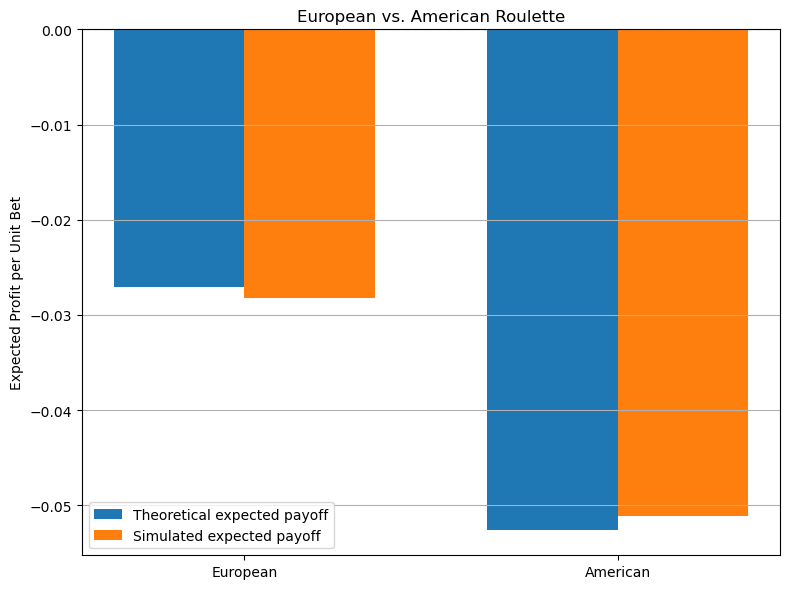

In [1]:
# ============================================================
# HOMEWORK 2.2 - PART I
# STANDALONE ROULETTE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

N = 1_000_000

SEED_EUROPEAN = 42

SEED_AMERICAN = 43


# Standard red numbers
red_numbers = np.array([
    1, 3, 5, 7, 9,
    12, 14, 16, 18,
    19, 21, 23, 25, 27,
    30, 32, 34, 36
])


# ============================================================
# EUROPEAN ROULETTE - THEORY
# ============================================================

p_E_win = 18 / 37

p_E_loss = 19 / 37


e_E = (
    p_E_win
    -
    p_E_loss
)


# Since payoff is always +1 or -1:
#
# E[X^2] = 1

var_E = (
    1
    -
    e_E**2
)


print("=" * 65)

print(
    "EUROPEAN ROULETTE - THEORETICAL RESULTS"
)

print("=" * 65)

print(
    "P(win) =",
    p_E_win
)

print(
    "P(loss) =",
    p_E_loss
)

print(
    "E[X] =",
    e_E
)

print(
    "Var(X) =",
    var_E
)


# ============================================================
# EUROPEAN ROULETTE - SIMULATION
# ============================================================

rng_E = np.random.default_rng(
    SEED_EUROPEAN
)


european_spins = rng_E.integers(
    0,
    37,
    size=N
)


european_wins = np.isin(
    european_spins,
    red_numbers
)


european_payoffs = np.where(
    european_wins,
    1.0,
    -1.0
)


sim_E_win = np.mean(
    european_wins
)


sim_E_loss = np.mean(
    ~european_wins
)


sim_E_mean = np.mean(
    european_payoffs
)


sim_E_var = np.var(
    european_payoffs
)


se_E = np.sqrt(
    var_E / N
)


z_E = (
    sim_E_mean
    -
    e_E
) / se_E


print()

print(
    "EUROPEAN ROULETTE - MONTE CARLO"
)

print("-" * 65)

print(
    "Number of spins =",
    N
)

print(
    "Simulated P(win) =",
    sim_E_win
)

print(
    "Simulated P(loss) =",
    sim_E_loss
)

print(
    "Simulated E[X] =",
    sim_E_mean
)

print(
    "Theoretical E[X] =",
    e_E
)

print(
    "Difference =",
    sim_E_mean - e_E
)

print(
    "Standard error =",
    se_E
)

print(
    "Difference in standard errors =",
    z_E
)

print(
    "Simulated Var(X) =",
    sim_E_var
)


if abs(z_E) < 4:

    print(
        "PASS: European roulette simulation "
        "agrees with theory."
    )

else:

    print(
        "WARNING: European roulette differs "
        "from theory more than expected."
    )


# ============================================================
# AMERICAN ROULETTE - THEORY
# ============================================================

p_A_win = 18 / 38

p_A_loss = 20 / 38


e_A = (
    p_A_win
    -
    p_A_loss
)


var_A = (
    1
    -
    e_A**2
)


print()

print("=" * 65)

print(
    "AMERICAN ROULETTE - THEORETICAL RESULTS"
)

print("=" * 65)

print(
    "P(win) =",
    p_A_win
)

print(
    "P(loss) =",
    p_A_loss
)

print(
    "E[X] =",
    e_A
)

print(
    "Var(X) =",
    var_A
)


# ============================================================
# AMERICAN ROULETTE - SIMULATION
#
# Code 37 represents the 00 pocket.
#
# 0      = 0
# 1-36   = normal numbers
# 37     = 00
# ============================================================

rng_A = np.random.default_rng(
    SEED_AMERICAN
)


american_spins = rng_A.integers(
    0,
    38,
    size=N
)


american_wins = np.isin(
    american_spins,
    red_numbers
)


american_payoffs = np.where(
    american_wins,
    1.0,
    -1.0
)


sim_A_win = np.mean(
    american_wins
)


sim_A_loss = np.mean(
    ~american_wins
)


sim_A_mean = np.mean(
    american_payoffs
)


sim_A_var = np.var(
    american_payoffs
)


se_A = np.sqrt(
    var_A / N
)


z_A = (
    sim_A_mean
    -
    e_A
) / se_A


print()

print(
    "AMERICAN ROULETTE - MONTE CARLO"
)

print("-" * 65)

print(
    "Number of spins =",
    N
)

print(
    "Simulated P(win) =",
    sim_A_win
)

print(
    "Simulated P(loss) =",
    sim_A_loss
)

print(
    "Simulated E[X] =",
    sim_A_mean
)

print(
    "Theoretical E[X] =",
    e_A
)

print(
    "Difference =",
    sim_A_mean - e_A
)

print(
    "Standard error =",
    se_A
)

print(
    "Difference in standard errors =",
    z_A
)

print(
    "Simulated Var(X) =",
    sim_A_var
)


if abs(z_A) < 4:

    print(
        "PASS: American roulette simulation "
        "agrees with theory."
    )

else:

    print(
        "WARNING: American roulette differs "
        "from theory more than expected."
    )


# ============================================================
# COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({

    "Game": [
        "European",
        "American"
    ],

    "Theoretical_P_Win": [
        p_E_win,
        p_A_win
    ],

    "Simulated_P_Win": [
        sim_E_win,
        sim_A_win
    ],

    "Theoretical_P_Loss": [
        p_E_loss,
        p_A_loss
    ],

    "Simulated_P_Loss": [
        sim_E_loss,
        sim_A_loss
    ],

    "Theoretical_EV": [
        e_E,
        e_A
    ],

    "Simulated_EV": [
        sim_E_mean,
        sim_A_mean
    ]

})


print()

print("=" * 65)

print(
    "EUROPEAN VS. AMERICAN ROULETTE"
)

print("=" * 65)

print()

print(
    comparison.to_string(
        index=False
    )
)


# ============================================================
# INDEPENDENCE CHECK
#
# Does winning become more likely after 5 losses?
#
# Use European roulette.
# ============================================================

wins = european_wins


# Find all positions where the previous 5 spins
# were losses.

previous_five_losses = (

    (~wins[:-5])
    &
    (~wins[1:-4])
    &
    (~wins[2:-3])
    &
    (~wins[3:-2])
    &
    (~wins[4:-1])
)


# Outcome immediately after those five losses

next_spin_wins = wins[5:]


number_of_five_loss_sequences = np.sum(
    previous_five_losses
)


number_of_next_wins = np.sum(
    previous_five_losses
    &
    next_spin_wins
)


conditional_win_probability = (
    number_of_next_wins
    /
    number_of_five_loss_sequences
)


print()

print("=" * 65)

print(
    "INDEPENDENCE / GAMBLER'S FALLACY CHECK"
)

print("=" * 65)

print(
    "Number of observed 5-loss sequences =",
    number_of_five_loss_sequences
)

print(
    "Theoretical P(win on any spin) =",
    p_E_win
)

print(
    "Simulated P(win after 5 losses) =",
    conditional_win_probability
)

print(
    "Difference =",
    conditional_win_probability
    -
    p_E_win
)


# Standard error for conditional sample

conditional_se = np.sqrt(

    p_E_win
    *
    (1 - p_E_win)

    /

    number_of_five_loss_sequences
)


conditional_z = (

    conditional_win_probability
    -
    p_E_win

) / conditional_se


print(
    "Conditional standard error =",
    conditional_se
)

print(
    "Difference in standard errors =",
    conditional_z
)


if abs(conditional_z) < 4:

    print()

    print(
        "PASS: Winning after 5 losses is "
        "consistent with the ordinary win "
        "probability."
    )

    print(
        "The previous losses do not make "
        "the next spin more likely to win."
    )

else:

    print()

    print(
        "WARNING: Conditional result differs "
        "more than expected."
    )


# ============================================================
# PLOT EXPECTED PAYOFF COMPARISON
# ============================================================

games = [
    "European",
    "American"
]


theoretical_values = [
    e_E,
    e_A
]


simulated_values = [
    sim_E_mean,
    sim_A_mean
]


x = np.arange(
    len(games)
)


width = 0.35


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    x - width / 2,

    theoretical_values,

    width,

    label="Theoretical expected payoff"
)


plt.bar(

    x + width / 2,

    simulated_values,

    width,

    label="Simulated expected payoff"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xticks(
    x,
    games
)


plt.ylabel(
    "Expected Profit per Unit Bet"
)


plt.title(
    "European vs. American Roulette"
)


plt.grid(
    True,
    axis="y"
)


plt.legend()


plt.tight_layout()


plt.savefig(
    "european_vs_american_roulette.png",
    dpi=300
)


plt.show()